In [269]:
# ANN Adaptive FIR Identification with ADALINE
# numpy/scipy/tensorflow/keras
#
# IC Ex2 - Setembro/2025 - Adolfo Bauchspiess 


import numpy as np
import matplotlib.pyplot as plt
import csv
from scipy import signal

print('Ex2 IC ENE/UnB 28/09/2024')

delays = 11   # order of the FIR teste n = 186 e mu = 0.01
mu = 0.084848    # learning rate
#band = '01'   # Choose '01' or '05':PRBS signal with [0-0.01] of Nyquist band
band = '05'   #                     or PRBS signal with [0-0.05] of Nyquist band
              # [0-1] band means a signal that can change as fasta as on each sample



print("--- Procedimento 1: Discretizando os Sistemas G(s) ---")
print(band)
Tab = 0.1


# --- Sistema 1: G1(s) = 1 / (s^2 + 0.2s + 1) ---
g1=signal.lti([1],(1, .2, 1)) 
# this also works!: g1=signal.cont2discrete((1,(1, .2, 1)),0.1,method='zoh')
num_g1 = [1]
den_g1 = [1, 0.2, 1]
g1_disc = signal.cont2discrete((num_g1, den_g1), Tab, method='zoh')
num_d1, den_d1 = g1_disc[0].flatten(), g1_disc[1].flatten()


# --- Sistema 2: G2(s) = 3 / (s^2 + 2s + 1) ---
g2=signal.lti([3],(1, 2, 1))
# this also works!: g1=signal.cont2discrete((1,(1, .2, 1)),0.1,method='zoh')
num_g2 = [3]
den_g2 = [1, 2, 1]
g2_disc = signal.cont2discrete((num_g2, den_g2), Tab, method='zoh')
num_d2, den_d2 = g2_disc[0].flatten(), g2_disc[1].flatten()

print("Discretização concluída.")
print(f"Sistema 1 Discreto (G1): Num={np.round(num_d1, 5)}, Den={np.round(den_d1, 5)}")
print(f"Sistema 2 Discreto (G2): Num={np.round(num_d2, 5)}, Den={np.round(den_d2, 5)}\n")


t1=np.linspace(0,79.9,800)   # first time interval, for g1
t2=np.linspace(80,119.9,400) # second time interval, for g2

Ex2 IC ENE/UnB 28/09/2024
--- Procedimento 1: Discretizando os Sistemas G(s) ---
05
Discretização concluída.
Sistema 1 Discreto (G1): Num=[0.      0.00496 0.00493], Den=[ 1.      -1.97031  0.9802 ]
Sistema 2 Discreto (G2): Num=[0.      0.01404 0.01313], Den=[ 1.      -1.80967  0.81873]



In [270]:
#u=idinput(1500,'PRBS',[0 0.01]); u=u';     # Matlab commands
#%u=zeros(size(u))+1
#[Y,Zf]=filter(gd.num{1,1},gd.den{1,1},u(1:800));
#[Y2]=filter(gd2.num{1,1},gd2.den{1,1},u(801:1500),Zf);

([<matplotlib.lines.Line2D at 0x1439b104710>],
 Text(0.5, 1.0, 'PRBS [0-0.05] of Nyquist Band'))

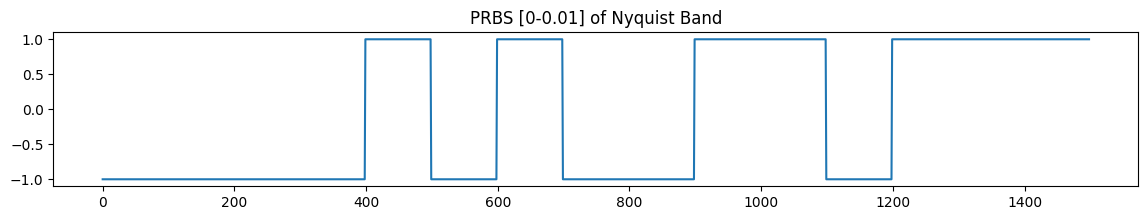

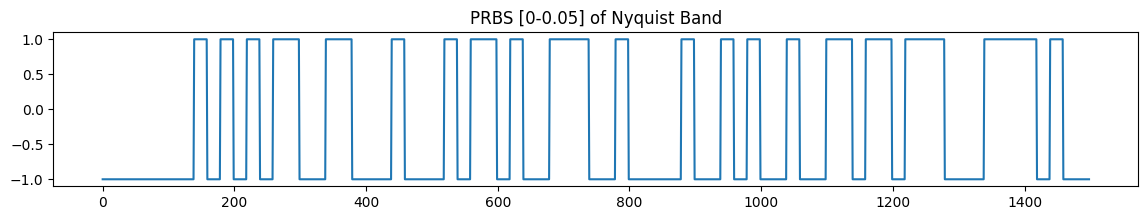

In [271]:
# load both PRBS signals from file 
data=np.genfromtxt('idinp.csv',dtype=float,delimiter=',',skip_header=1)    

u01=data[:,0]
u05=data[:,1]
plt.figure(1,figsize=(14,2))
plt.plot(u01,label='u01'),plt.title('PRBS [0-0.01] of Nyquist Band')
plt.figure(2,figsize=(14,2))
plt.plot(u05,label='u05'),plt.title('PRBS [0-0.05] of Nyquist Band')


In [272]:
u1=u01[0:800]              # initializa vectors
u2=u01[800:1200]  

if band=='01':             # i=0,1 choose one of the signals, .01 or 0.05 band.
        u1=u01[0:800]     
        u2=u01[800:1200]  
        to1,y1,x1=signal.lsim(g1,u01[0:800],t1)
        to2,y2,x2=signal.lsim(g2,u01[800:1200],t2,X0=x1[-1])
else:
        u1=u05[0:800]     
        u2=u05[800:1200]  
        to1,y1,x1=signal.lsim(g1,u05[0:800],t1)
        to2,y2,x2=signal.lsim(g2,u05[800:1200],t2,X0=x1[-1])
        
t=np.concatenate((t1,t2))
u=np.concatenate((u1,u2))
y=np.concatenate((y1,y2))

In [273]:
# u  0 1 2 3 4 5 6 7 8 9 10 11...     1197 1198 1199 1200
#tdl 0
#w   0
#ys  u[0]*w[0]
#tdl 1 0
#w   1 0
#ys  u[1]*w[1] + u[0]*w[0]
#tdl 2 1 0
#w   2 1 0
#ys  u[2]*w[2] + u[1]*w[1] + u[0]*w[0]

def adaline(u, *arg):                          # receives (u) or ,(u,w) - produces ys
                                               # 
    w = np.zeros(delays,dtype=float)           # Initialize weights
    wt= np.zeros((len(u),delays),dtype=float)  # register time evolution of the weights
    ys= np.zeros(len(u), dtype=float)
    et= np.zeros(len(u), dtype=float)
    err=0
    
    if len(arg)==0: adapt=1                    # adapt weights w
    else: w = arg;  adapt=0                    # receive and mantain w - simulate only
            
    # fill in "acausal" zeros , for t<0
    ud=np.zeros(delays,dtype=float)
    ue=np.insert(ud,delays,u)    

    for i in range(len(u)):      
        for j in range(delays): ys[i]+=ue[i-j]*w[j]  # simulate ADALINE
        for j in range(delays): 
            et[i]=y[i]-ys[i]
            if adapt==1:
                w[j]+=mu*et[i]*ue[i-j]               # Widrow-Hoff delta rule
                wt[i,j] = w[j]                       # store w history
        err+=(y[i]-ys[i])**2
    mse=err/len(u)
    
    return ys, et, mse, wt

In [274]:
# run adaptive ADALINE
ya, ea, msea, wt = adaline(u)
print(msea)

# run with Fixed NN weights - the last values from the previous run 
yf, ef, msef, wr =adaline(u,*wt[-1,:])


0.17692316067699101


In [275]:
# NEWLIND
# y1 = w0*1 + w1*u1[0] + w2*u1[-1] + w3*u1[-2] + ...
# y2 = w0*1 + w1*u2[0] + w2*u2[-1] + w3*u2[-2] + ...
# ...
# yN = w0*1 + w1*u2[0] + w2*u2[-1] + w3*u2[-2] + ...
#
#                               Y_Nx1   - Measurements
# Y = U*Psi'                    U_NxM   - Regressors    
# U'Y = U'U*Psi'                Psi_1xM - Parameter Vector
# Psi'= (U'U)-1 U' Y            (U'U)-1 U' - Pseudoinverse - MMQ  

# NEWLIND - Design a ADALINE using all samples at once: the pseudoinverse
U=np.zeros((len(u)+delays,delays))
for j in range(delays):         # build U with copies of shifted u
    U[j:len(u)+j,j]=u

Y=np.zeros((len(u)+delays))
Y[0:len(y)]=y

#wd = inv(U'U)*U'*y
wd = np.matmul(np.matmul(np.linalg.inv(np.matmul(np.transpose(U),U)),np.transpose(U)),Y)


# NEWLIND Fixed weights wd - Designed
yd, ed, msed, wr =adaline(u,*wd)

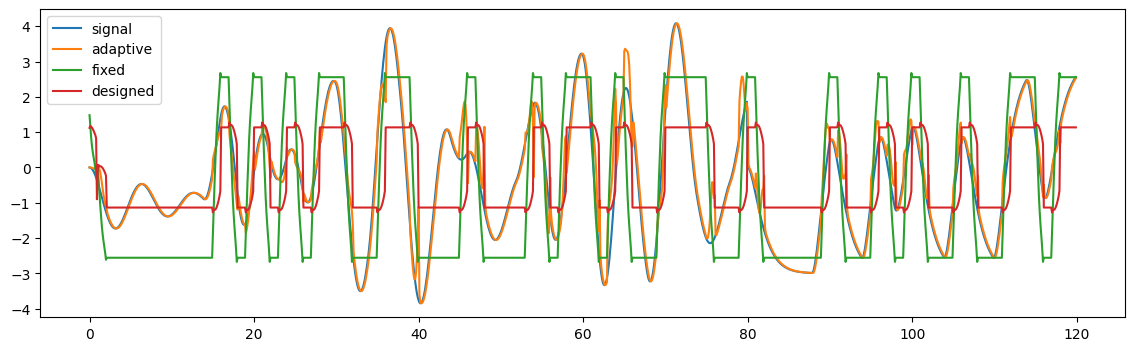

In [276]:
plt.figure(1,figsize=(14,4))
plt.plot(t, y,label='signal')
plt.plot(t, ya,label='adaptive')
plt.plot(t, yf,label='fixed')
plt.plot(t, yd,label='designed');
plt.legend()

Grafico da entrada y, ou seja, a saida do sistema real.


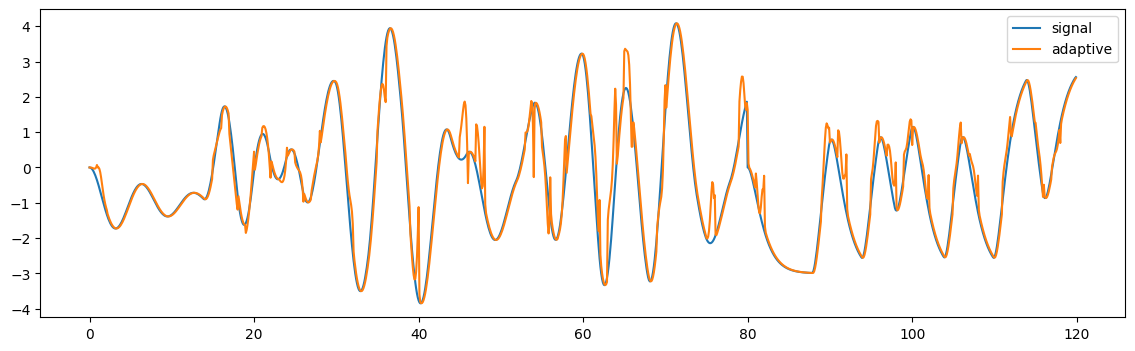

In [277]:
print('Grafico da entrada y, ou seja, a saida do sistema real.')

plt.figure(2,figsize=(14,4))
plt.plot(t, y,label='signal')
plt.plot(t, ya,label='adaptive')
plt.legend()

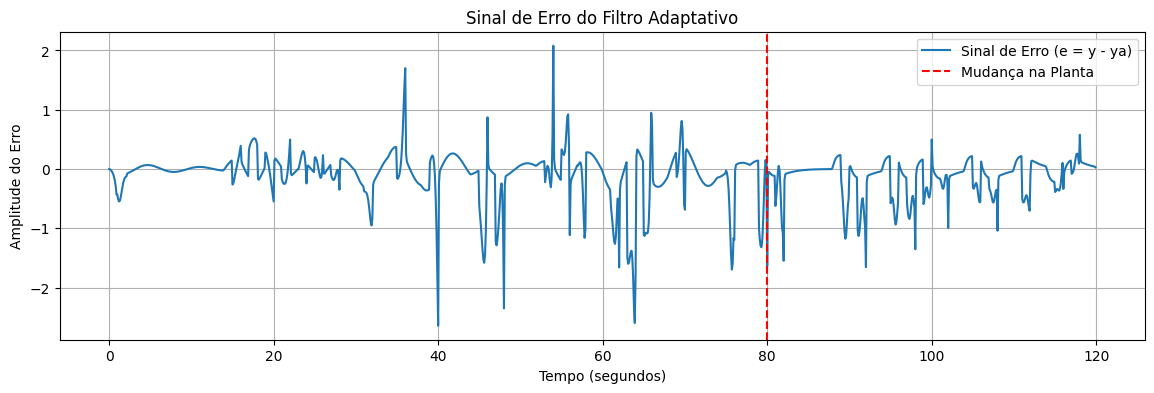

In [278]:
plt.figure(figsize=(14, 4))
plt.plot(t, ea, label='Sinal de Erro (e = y - ya)')
plt.title('Sinal de Erro do Filtro Adaptativo')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Amplitude do Erro')
plt.axvline(x=80, color='r', linestyle='--', label='Mudança na Planta')
plt.grid(True)
plt.legend()
plt.show()

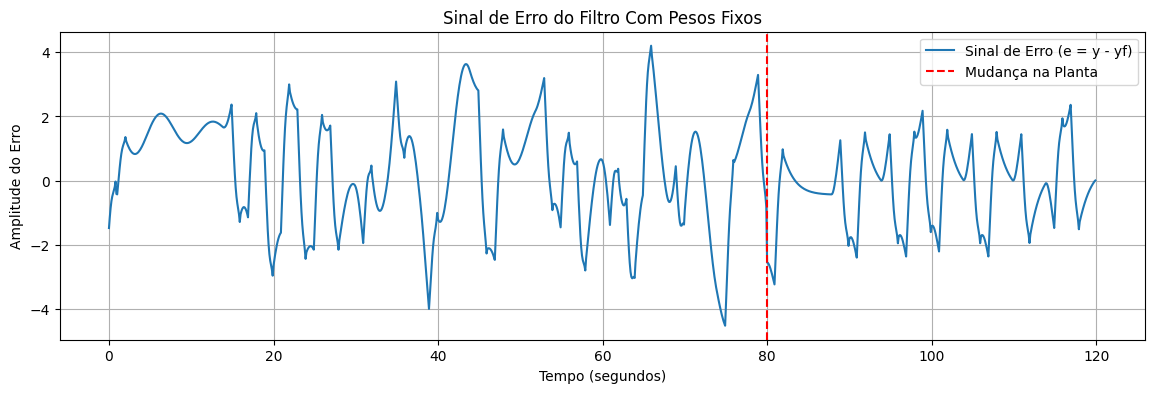

In [279]:
plt.figure(figsize=(14, 4))
plt.plot(t, ef, label='Sinal de Erro (e = y - yf)')
plt.title('Sinal de Erro do Filtro Com Pesos Fixos')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Amplitude do Erro')
plt.axvline(x=80, color='r', linestyle='--', label='Mudança na Planta')
plt.grid(True)
plt.legend()
plt.show()

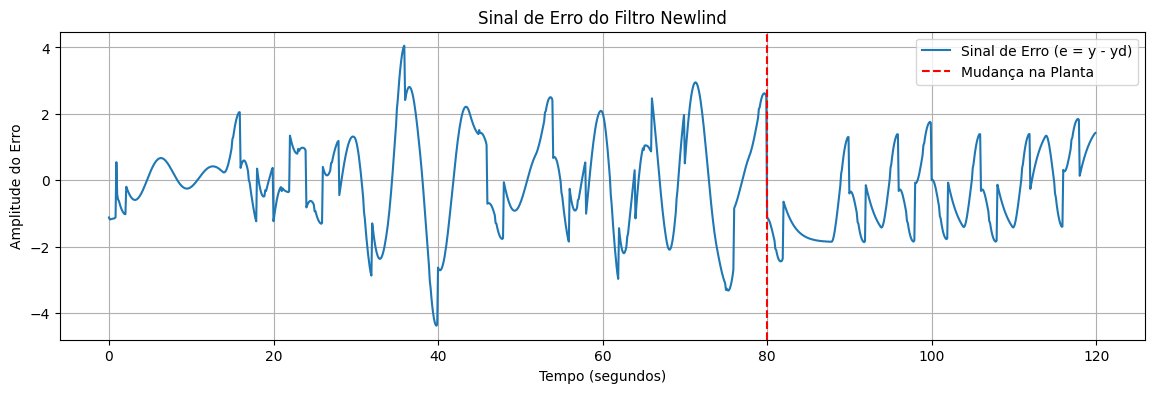

In [280]:
plt.figure(figsize=(14, 4))
plt.plot(t, ed, label='Sinal de Erro (e = y - yd)')
plt.title('Sinal de Erro do Filtro Newlind')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Amplitude do Erro')
plt.axvline(x=80, color='r', linestyle='--', label='Mudança na Planta')
plt.grid(True)
plt.legend()
plt.show()

In [281]:
#Para band = '05'
#Melhor configuração encontrada: delays = 11, mu = 0.084848
#Menor MSE obtido: 0.17692316067699101
if band == '0': # colocado essa condição para não ter que executar todas as vezes que compilar
    delays_teste = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,
                    21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,
                    41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,
                    61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,
                    81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100] # valores escolhidos arbitrariamente

    mu_teste = [0.010000,0.011919,0.013838,0.015758,0.017677,0.019596,0.021515,0.023434,0.025354,0.027273,
                0.029192,0.031111,0.033030,0.034949,0.036869,0.038788,0.040707,0.042626,0.044545,0.046465,
                0.048384,0.050303,0.052222,0.054141,0.056061,0.057980,0.059899,0.061818,0.063737,0.065657,
                0.067576,0.069495,0.071414,0.073333,0.075253,0.077172,0.079091,0.081010,0.082929,0.084848,
                0.086768,0.088687,0.090606,0.092525,0.094444,0.096364,0.098283,0.100202,0.102121,0.104040,
                0.105960,0.107879,0.109798,0.111717,0.113636,0.115556,0.117475,0.119394,0.121313,0.123232,
                0.125152,0.127071,0.128990,0.130909,0.132828,0.134747,0.136667,0.138586,0.140505,0.142424,
                0.144343,0.146263,0.148182,0.150101,0.152020,0.153939,0.155859,0.157778,0.159697,0.161616,
                0.163535,0.165455,0.167374,0.169293,0.171212,0.173131,0.175051,0.176970,0.178889,0.180808,
                0.182727,0.184646,0.186566,0.188485,0.190404,0.192323,0.194242,0.196162,0.198081,0.200000] # valores escolhidos arbitrariamente

    resultados_mse = {} # Guardar os valores de erros que serão calculados para depois comparar qual o menor

    
    for n_delays in delays_teste:
        for taxa_mu in mu_teste:
        
            mu = taxa_mu
            delays = n_delays
            
            ya, e, msea, wt = adaline(u) # Chamando a função para verificar todos os MSE

            print(f"Testando com delays = {n_delays} e mu = {taxa_mu} o erro é {msea}")
    
            resultados_mse[(n_delays, taxa_mu)] = msea 


    melhor_config = min(resultados_mse, key=resultados_mse.get)
    menor_mse = resultados_mse[melhor_config]

    print(f"\nMelhor configuração encontrada: delays = {melhor_config[0]}, mu = {melhor_config[1]}")
    print(f"Menor MSE obtido: {menor_mse}")
